<a href="https://colab.research.google.com/github/Rakza31/Tutorial-6-SVM/blob/main/SVM.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
pip install scikit-learn

In [8]:
# Load and understand the dataset
from sklearn.datasets import load_breast_cancer
import matplotlib.pyplot as plt
from sklearn.inspection import DecisionBoundaryDisplay
from sklearn.svm import SVC

cancer = load_breast_cancer()
X = cancer.data[:, :2]
y = cancer.target

print("Dataset shape:", cancer.data.shape)
print("Selected features:", cancer.feature_names[:2])
print("Target classes:", cancer.target_names)

Dataset shape: (569, 30)
Selected features: ['mean radius' 'mean texture']
Target classes: ['malignant' 'benign']


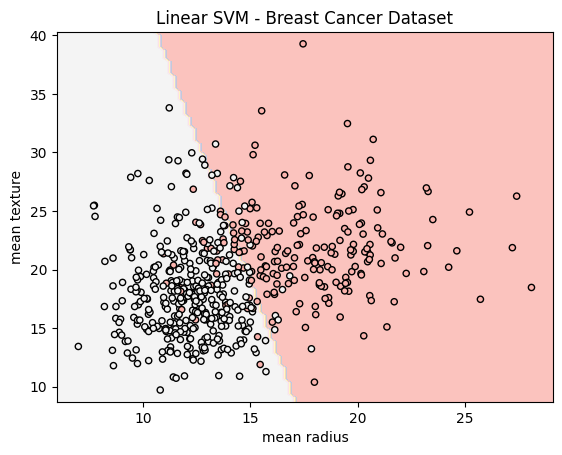

In [9]:
# Linear SVM and its visualization
linear_svm = SVC(kernel="linear", C=1)
linear_svm.fit(X, y)

DecisionBoundaryDisplay.from_estimator(
    linear_svm,
    X,
    response_method="predict",
    alpha=0.8,
    cmap="Pastel1",
    xlabel=cancer.feature_names[0],
    ylabel=cancer.feature_names[1]
)


plt.scatter(
    X[:, 0], X[:, 1],
    c=y, s=20, edgecolors="k", cmap="Pastel1"
)
plt.title("Linear SVM - Breast Cancer Dataset")
plt.show()

In [11]:
X = cancer.data[:, :2]
y = cancer.target

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

linear_svm = SVC(kernel="linear", C=1)
linear_svm.fit(X_train, y_train)

linear_pred = linear_svm.predict(X_test)

print("Linear SVM Accuracy:", round(accuracy_score(y_test, linear_pred) * 100, 2), "%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, linear_pred))
print("\nClassification Report:\n",
      classification_report(y_test, linear_pred, target_names=cancer.target_names))

Linear SVM Accuracy: 86.84 %

Confusion Matrix:
 [[34  8]
 [ 7 65]]

Classification Report:
               precision    recall  f1-score   support

   malignant       0.83      0.81      0.82        42
      benign       0.89      0.90      0.90        72

    accuracy                           0.87       114
   macro avg       0.86      0.86      0.86       114
weighted avg       0.87      0.87      0.87       114



Non-Linear SVM Accuracy: 90.35 %

Confusion Matrix:
 [[37  5]
 [ 6 66]]

Classification Report:
               precision    recall  f1-score   support

   malignant       0.86      0.88      0.87        42
      benign       0.93      0.92      0.92        72

    accuracy                           0.90       114
   macro avg       0.90      0.90      0.90       114
weighted avg       0.90      0.90      0.90       114



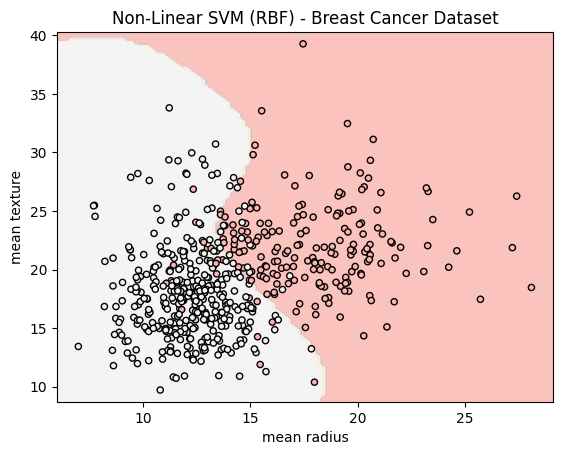

In [12]:
# Non-Linear SVM
nonlinear_svm = SVC(kernel="rbf", C=1, gamma="scale")
nonlinear_svm.fit(X_train, y_train)

nonlinear_pred = nonlinear_svm.predict(X_test)

print("Non-Linear SVM Accuracy:", round(accuracy_score(y_test, nonlinear_pred) * 100, 2), "%")
print("\nConfusion Matrix:\n", confusion_matrix(y_test, nonlinear_pred))
print("\nClassification Report:\n",
      classification_report(y_test, nonlinear_pred, target_names=cancer.target_names))
nonlinear_svm = SVC(kernel="rbf", C=1, gamma="scale")
nonlinear_svm.fit(X, y)

DecisionBoundaryDisplay.from_estimator(
    nonlinear_svm,
    X,
    response_method="predict",
    alpha=0.8,
    cmap="Pastel1",
    xlabel=cancer.feature_names[0],
    ylabel=cancer.feature_names[1]
)

plt.scatter(
    X[:, 0], X[:, 1],
    c=y, s=20, edgecolors="k", cmap="Pastel1"
)
plt.title("Non-Linear SVM (RBF) - Breast Cancer Dataset")
plt.show()